# Student Dropout Prediction System

The app's reported benchmark is a Random Forest with engineered academic features. Its saved test accuracy is **78.53%**.

The target remains multiclass: `Dropout`, `Enrolled`, and `Graduate`.

The Flask application only loads saved model artifacts; it does not train models at startup. The 11-feature experiment later in this notebook is a separate comparison, not the app's benchmark.

## Main result: current app benchmark

The cell below reads the saved app benchmark results. Run this first to see the one headline accuracy to report. Later notebook cells contain a separate 11-feature experiment and may show different scores.

In [44]:
from pathlib import Path

import pandas as pd

project_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'student_dropout_prediction']
project_dir = next(
    (candidate for candidate in project_candidates if (candidate / 'models' / 'model_results.csv').exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError('Could not find models/model_results.csv. Open the notebook from the project directory.')

app_results = pd.read_csv(project_dir / 'models' / 'model_results.csv')
app_result = app_results[
    app_results['Experiment'].astype(str).str.contains('Experiment 2', case=False, na=False)
    & app_results['Model'].astype(str).str.casefold().eq('random forest')
]
if app_result.empty:
    raise ValueError('The saved app Random Forest Experiment 2 result was not found.')

app_accuracy = float(app_result.iloc[0]['Accuracy'])
print(f"Current app model: {app_result.iloc[0]['Model']} ({app_result.iloc[0]['Experiment']})")
print(f'App benchmark test accuracy: {app_accuracy:.2%}')

Current app model: Random Forest (Experiment 2 - raw plus academic features)
App benchmark test accuracy: 78.53%


In [29]:
# Supplemental 11-feature comparison: this is not the app benchmark
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, make_scorer, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

SELECTED_FEATURES = [
    'Gender',
    'Age at enrollment',
    'Course',
    'Previous qualification (grade)',
    'Admission grade',
    'Tuition fees up to date',
    'Scholarship holder',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
]


In [21]:
# 2. Load the project dataset locally
project_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'student_dropout_prediction']
project_dir = next(
    (candidate for candidate in project_candidates if (candidate / 'dataset' / 'data.csv').exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError('Could not find student_dropout_prediction/dataset/data.csv from the current working directory.')

dataset_path = project_dir / 'dataset' / 'data.csv'
df = pd.read_csv(dataset_path, sep=';')
df.columns = [str(column).strip() for column in df.columns]

print(f'Dataset loaded: {dataset_path}')
print(f'Shape: {df.shape}')
print('Available columns:', list(df.columns))
display(df.head())

Dataset loaded: d:\sdps\student_dropout_prediction\dataset\data.csv
Shape: (4424, 37)
Available columns: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular un

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [45]:
# 3. Inspect and clean the real dataset
df = df.replace(r'^\s*$', np.nan, regex=True)
print('Missing values before cleaning:')
print(df.isna().sum().sort_values(ascending=False).head())
print('Duplicate rows:', int(df.duplicated().sum()))
df = df.drop_duplicates().dropna(subset=['Target']).reset_index(drop=True)
missing_features = [column for column in SELECTED_FEATURES if column not in df.columns]
if missing_features:
    raise ValueError(f'Missing selected columns: {missing_features}')
print('Cleaned shape:', df.shape)
print('Target distribution:')
print(df['Target'].value_counts())


Missing values before cleaning:
Marital status                0
Application mode              0
Application order             0
Course                        0
Daytime/evening attendance    0
dtype: int64
Duplicate rows: 0
Cleaned shape: (4424, 37)
Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [46]:
# 4. Select exactly the 11 features for the legacy comparison
X = df[SELECTED_FEATURES].copy()
label_encoder = LabelEncoder()
y = pd.Series(label_encoder.fit_transform(df['Target'].astype(str).str.strip()), index=df.index)
print('Selected feature count:', len(SELECTED_FEATURES))
print('Selected features:', SELECTED_FEATURES)
print('Target classes:', label_encoder.classes_.tolist())


Selected feature count: 11
Selected features: ['Gender', 'Age at enrollment', 'Course', 'Previous qualification (grade)', 'Admission grade', 'Tuition fees up to date', 'Scholarship holder', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)']
Target classes: ['Dropout', 'Enrolled', 'Graduate']


In [47]:
# 5. Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))


Training rows: 3539
Test rows: 885


In [48]:
# 6. Leakage-safe preprocessing pipeline
numeric_columns = X.select_dtypes(include=['number']).columns.tolist()
categorical_columns = [column for column in X.columns if column not in numeric_columns]

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), numeric_columns),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]), categorical_columns),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [49]:
# 7. Define baseline models and tuned search spaces
baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=250, class_weight='balanced', random_state=42, n_jobs=-1),
    'SVM': SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(
        objective='multi:softprob',
        num_class=3,
        eval_metric='mlogloss',
        random_state=42,
        n_jobs=2,
    ),
}

tuned_specs = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
        {
            'model__C': [0.1, 0.5, 1.0, 2.0, 5.0],
            'model__solver': ['lbfgs', 'liblinear'],
        },
    ),
    'Decision Tree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=42),
        {
            'model__max_depth': [None, 6, 10, 14, 20],
            'model__min_samples_split': [2, 5, 10],
            'model__min_samples_leaf': [1, 2, 5],
        },
    ),
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
        {
            'model__n_estimators': [200, 400],
            'model__max_depth': [None, 12, 20],
            'model__min_samples_split': [2, 5],
            'model__min_samples_leaf': [1, 2],
            'model__max_features': ['sqrt', 'log2'],
        },
    ),
    'SVM': (
        SVC(probability=True, class_weight='balanced', random_state=42),
        {
            'model__C': [0.5, 1.0, 2.0, 5.0],
            'model__kernel': ['rbf', 'linear'],
            'model__gamma': ['scale', 'auto'],
        },
    ),
    'XGBoost': (
        XGBClassifier(
            objective='multi:softprob',
            num_class=3,
            eval_metric='mlogloss',
            random_state=42,
            n_jobs=2,
        ),
        {
            'model__n_estimators': [200, 400],
            'model__max_depth': [3, 5, 7],
            'model__learning_rate': [0.03, 0.07, 0.1],
            'model__subsample': [0.8, 1.0],
            'model__colsample_bytree': [0.8, 1.0],
        },
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
trained_models = {}
baseline_models_fitted = {}
baseline_results = []
tuned_results = []
confusion_matrices = {}


In [50]:
# 8. Evaluate baselines, then tune using training data only
from sklearn.utils.class_weight import compute_sample_weight

encoded_dropout = int(label_encoder.transform(['Dropout'])[0])
class_order = [int(label_encoder.transform([label])[0]) for label in ['Dropout', 'Enrolled', 'Graduate']]
xgb_sample_weight = compute_sample_weight(class_weight='balanced', y=y_train)
cv_scoring = {
    'f1_macro': make_scorer(f1_score, average='macro'),
    'dropout_f1': make_scorer(f1_score, labels=[encoded_dropout], average='macro', zero_division=0),
    'dropout_recall': make_scorer(recall_score, labels=[encoded_dropout], average='macro', zero_division=0),
}


def evaluate_model(model_name, fitted_model, X_eval, y_eval, result_kind):
    y_pred = fitted_model.predict(X_eval)
    y_probability = fitted_model.predict_proba(X_eval) if hasattr(fitted_model, 'predict_proba') else None
    classes = getattr(fitted_model, 'classes_', np.unique(y_eval))
    return {
        'Model': model_name,
        'Result': result_kind,
        'Accuracy': accuracy_score(y_eval, y_pred),
        'Precision': precision_score(y_eval, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_eval, y_pred, average='macro', zero_division=0),
        'F1-score': f1_score(y_eval, y_pred, average='macro', zero_division=0),
        'Dropout Precision': precision_score(y_eval, y_pred, labels=[encoded_dropout], average='macro', zero_division=0),
        'Dropout Recall': recall_score(y_eval, y_pred, labels=[encoded_dropout], average='macro', zero_division=0),
        'Dropout F1-score': f1_score(y_eval, y_pred, labels=[encoded_dropout], average='macro', zero_division=0),
        'ROC-AUC': roc_auc_score(y_eval, y_probability, multi_class='ovr', labels=classes) if y_probability is not None else np.nan,
        'Confusion Matrix': confusion_matrix(y_eval, y_pred, labels=class_order).tolist(),
    }


# Baselines are fitted on X_train and evaluated once on the untouched test set.
for model_name, estimator in baseline_models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('model', estimator)])
    fit_kwargs = {'model__sample_weight': xgb_sample_weight} if model_name == 'XGBoost' else {}
    pipeline.fit(X_train, y_train, **fit_kwargs)
    baseline_models_fitted[model_name] = pipeline
    baseline_results.append(evaluate_model(model_name, pipeline, X_test, y_test, 'Baseline test'))

# Hyperparameters are selected only by 5-fold CV inside X_train.
for model_name, (estimator, parameter_grid) in tuned_specs.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('model', estimator)])
    search = GridSearchCV(
        pipeline,
        parameter_grid,
        scoring=cv_scoring,
        refit='dropout_f1',
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
    )
    fit_kwargs = {'model__sample_weight': xgb_sample_weight} if model_name == 'XGBoost' else {}
    search.fit(X_train, y_train, **fit_kwargs)
    trained_models[model_name] = search.best_estimator_
    result = evaluate_model(model_name, search.best_estimator_, X_test, y_test, 'Tuned test')
    result['CV F1-macro'] = search.cv_results_['mean_test_f1_macro'][search.best_index_]
    result['CV Dropout F1-score'] = search.cv_results_['mean_test_dropout_f1'][search.best_index_]
    result['CV Dropout Recall'] = search.cv_results_['mean_test_dropout_recall'][search.best_index_]
    result['Best Parameters'] = search.best_params_
    tuned_results.append(result)
    confusion_matrices[model_name] = result['Confusion Matrix']
    print(f'{model_name} best parameters: {search.best_params_}')
    print(f'{model_name} CV dropout F1: {result["CV Dropout F1-score"]:.4f}')
    print(f'{model_name} CV dropout recall: {result["CV Dropout Recall"]:.4f}')

baseline_results_df = pd.DataFrame(baseline_results)
tuned_results_df = pd.DataFrame(tuned_results)

app_results_path = project_dir / 'models' / 'model_results.csv'
if not app_results_path.exists():
    raise FileNotFoundError(f'App model results not found: {app_results_path}')
app_results_df = pd.read_csv(app_results_path)
app_result_rows = app_results_df[
    app_results_df['Experiment'].astype(str).str.contains('Experiment 2', case=False, na=False)
    & app_results_df['Model'].astype(str).str.casefold().eq('random forest')
]
if app_result_rows.empty:
    raise ValueError('The saved app Random Forest Experiment 2 result was not found.')
app_result = app_result_rows.iloc[0]
app_reference = {
    'Model': 'Random Forest (app)',
    'Result': 'App benchmark - engineered features',
    'Accuracy': app_result['Accuracy'],
    'Precision': app_result['Precision'],
    'Recall': app_result['Recall'],
    'F1-score': app_result['Macro F1'],
    'Weighted F1': app_result['Weighted F1'],
    'ROC-AUC': app_result['ROC-AUC'],
}
comparison_display_df = pd.concat(
    [baseline_results_df, pd.DataFrame([app_reference])], ignore_index=True
)
print('Baseline models use 11 selected features. The app benchmark uses engineered features; compare as separate experiments.')
display(comparison_display_df.drop(columns=['Confusion Matrix'], errors='ignore'))
print('Tuned test results:')
display(tuned_results_df.drop(columns=['Confusion Matrix']))


Logistic Regression best parameters: {'model__C': 0.5, 'model__solver': 'liblinear'}
Logistic Regression CV dropout F1: 0.7513
Logistic Regression CV dropout recall: 0.7124
Decision Tree best parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10}
Decision Tree CV dropout F1: 0.7408
Decision Tree CV dropout recall: 0.6552
Random Forest best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Random Forest CV dropout F1: 0.7833
Random Forest CV dropout recall: 0.7414
SVM best parameters: {'model__C': 2.0, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
SVM CV dropout F1: 0.7559
SVM CV dropout recall: 0.6702
XGBoost best parameters: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 7, 'model__n_estimators': 200, 'model__subsample': 0.8}
XGBoost CV dropout F1: 0.7774
XGBoost CV dropout recall: 0.7177
Baseline

,Model,Result,Accuracy,Precision,Recall,F1-score,Dropout Precision,Dropout Recall,Dropout F1-score,ROC-AUC,Weighted F1
0,Logistic Regression,Baseline test,0.688136,0.680933,0.670788,0.657151,0.841860,0.637324,0.725451,0.840873,NaN
1,Decision Tree,Baseline test,0.659887,0.596218,0.597992,0.596960,0.662021,0.669014,0.665499,0.711479,NaN
2,Random Forest,Baseline test,0.740113,0.672950,0.641722,0.647668,0.770677,0.721831,0.745455,0.861800,NaN
3,SVM,Baseline test,0.702825,0.692862,0.683443,0.668837,0.849515,0.616197,0.714286,0.861082,NaN
4,XGBoost,Baseline test,0.722034,0.664028,0.661451,0.662146,0.772727,0.718310,0.744526,0.854693,NaN
5,Random Forest (app),App benchmark - engineered features,0.785311,0.743293,0.707209,0.718820,NaN,NaN,NaN,0.886263,0.775353


Tuned test results:


,Model,Result,Accuracy,Precision,Recall,F1-score,Dropout Precision,Dropout Recall,Dropout F1-score,ROC-AUC,CV F1-macro,CV Dropout F1-score,CV Dropout Recall,Best Parameters
0,Logistic Regression,Tuned test,0.718644,0.653116,0.639808,0.644552,0.787755,0.679577,0.729679,0.835042,0.652371,0.751348,0.712366,"{'model__C': 0.5, 'model__solver': 'liblinear'}"
1,Decision Tree,Tuned test,0.661017,0.662083,0.650843,0.635349,0.813333,0.644366,0.719057,0.845170,0.661883,0.740846,0.655240,"{'model__max_depth': 6, 'model__min_samples_le..."
2,Random Forest,Tuned test,0.741243,0.680197,0.662611,0.669015,0.797665,0.721831,0.757856,0.864097,0.688554,0.783334,0.741417,"{'model__max_depth': None, 'model__max_feature..."
3,SVM,Tuned test,0.699435,0.692228,0.680258,0.666331,0.858537,0.619718,0.719836,0.860893,0.677834,0.755858,0.670152,"{'model__C': 2.0, 'model__gamma': 'scale', 'mo..."
4,XGBoost,Tuned test,0.732203,0.690525,0.689966,0.685313,0.809129,0.686620,0.742857,0.872240,0.697845,0.777420,0.717664,"{'model__colsample_bytree': 0.8, 'model__learn..."


In [51]:
# 9. Inspect tuned confusion matrices
for model_name, matrix in confusion_matrices.items():
    print(f'{model_name} confusion matrix (rows/columns: Dropout, Enrolled, Graduate):')
    print(np.array(matrix))


Logistic Regression confusion matrix (rows/columns: Dropout, Enrolled, Graduate):
[[193  56  35]
 [ 35  59  65]
 [ 17  41 384]]
Decision Tree confusion matrix (rows/columns: Dropout, Enrolled, Graduate):
[[183  78  23]
 [ 27  99  33]
 [ 15 124 303]]
Random Forest confusion matrix (rows/columns: Dropout, Enrolled, Graduate):
[[205  34  45]
 [ 40  61  58]
 [ 12  40 390]]
SVM confusion matrix (rows/columns: Dropout, Enrolled, Graduate):
[[176  80  28]
 [ 21 104  34]
 [  8  95 339]]
XGBoost confusion matrix (rows/columns: Dropout, Enrolled, Graduate):
[[195  57  32]
 [ 33  89  37]
 [ 13  65 364]]


In [52]:
# 10. Select the final model using training-CV metrics only
comparison_columns = [
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1-score',
    'Dropout Precision', 'Dropout Recall', 'Dropout F1-score',
    'CV F1-macro', 'CV Dropout F1-score', 'CV Dropout Recall', 'ROC-AUC',
]
final_comparison = tuned_results_df.sort_values(
    ['CV Dropout F1-score', 'CV Dropout Recall', 'CV F1-macro'],
    ascending=False,
).reset_index(drop=True)
selected_model_name = final_comparison.iloc[0]['Model']
selected_result = final_comparison.iloc[0]

print('Final tuned-model comparison on the untouched test set:')
display(final_comparison[comparison_columns].style.format({column: '{:.4f}' for column in comparison_columns if column != 'Model'}))
print('\nBest parameters for every tuned model:')
for _, row in final_comparison.iterrows():
    print(f"{row['Model']}: {row['Best Parameters']}")

base_paper_accuracy = 0.87
best_test_accuracy = float(selected_result['Accuracy'])
difference_from_paper = best_test_accuracy - base_paper_accuracy
print(f'\nBase paper best reported accuracy: {base_paper_accuracy:.2%}')
print(f'Best actual final test accuracy: {best_test_accuracy:.2%}')
print(f'Difference from base paper: {difference_from_paper * 100:+.2f} percentage points')
print(f'Selected final model by CV metrics: {selected_model_name}')
print(f"Final test dropout precision: {selected_result['Dropout Precision']:.4f}")
print(f"Final test dropout recall: {selected_result['Dropout Recall']:.4f}")
print(f"Final test dropout F1-score: {selected_result['Dropout F1-score']:.4f}")
print(f"Final test ROC-AUC: {selected_result['ROC-AUC']:.4f}")
print('The test set was not used for tuning or model selection.')


Final tuned-model comparison on the untouched test set:


,Model,Accuracy,Precision,Recall,F1-score,Dropout Precision,Dropout Recall,Dropout F1-score,CV F1-macro,CV Dropout F1-score,CV Dropout Recall,ROC-AUC
0,Random Forest,0.7412,0.6802,0.6626,0.6690,0.7977,0.7218,0.7579,0.6886,0.7833,0.7414,0.8641
1,XGBoost,0.7322,0.6905,0.6900,0.6853,0.8091,0.6866,0.7429,0.6978,0.7774,0.7177,0.8722
2,SVM,0.6994,0.6922,0.6803,0.6663,0.8585,0.6197,0.7198,0.6778,0.7559,0.6702,0.8609
3,Logistic Regression,0.7186,0.6531,0.6398,0.6446,0.7878,0.6796,0.7297,0.6524,0.7513,0.7124,0.8350
4,Decision Tree,0.6610,0.6621,0.6508,0.6353,0.8133,0.6444,0.7191,0.6619,0.7408,0.6552,0.8452



Best parameters for every tuned model:
Random Forest: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}
XGBoost: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 7, 'model__n_estimators': 200, 'model__subsample': 0.8}
SVM: {'model__C': 2.0, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Logistic Regression: {'model__C': 0.5, 'model__solver': 'liblinear'}
Decision Tree: {'model__max_depth': 6, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10}

Base paper best reported accuracy: 87.00%
Best actual final test accuracy: 74.12%
Difference from base paper: -12.88 percentage points
Selected final model by CV metrics: Random Forest
Final test dropout precision: 0.7977
Final test dropout recall: 0.7218
Final test dropout F1-score: 0.7579
Final test ROC-AUC: 0.8641
The test set was not used for tuning or model selection.


In [53]:
# 11. Save notebook experiment artifacts separately from the Flask model
output_dir = project_dir / 'ml_training' / 'notebook_outputs'
output_dir.mkdir(exist_ok=True, parents=True)

# This notebook's selection method is exploratory; do not replace the production model.
joblib.dump(trained_models[selected_model_name], output_dir / 'best_model.pkl')
for model_name, pipeline in trained_models.items():
    file_name = model_name.lower().replace(' ', '_') + '.pkl'
    joblib.dump(pipeline, output_dir / file_name)

fitted_preprocessor = trained_models[selected_model_name].named_steps['preprocessor']
joblib.dump(fitted_preprocessor, output_dir / 'preprocessor.pkl')
joblib.dump({
    'columns': SELECTED_FEATURES,
    'selected_features': SELECTED_FEATURES,
    'numeric_columns': numeric_columns,
    'categorical_columns': categorical_columns,
    'categorical_values': {column: sorted(X[column].dropna().astype(str).unique().tolist()) for column in categorical_columns},
    'target_column': 'Target',
    'target_classes': label_encoder.classes_.tolist(),
    'selection_rule': 'Highest tuned test Dropout F1-score, then Dropout Recall, then CV F1-macro.',
}, output_dir / 'feature_columns.pkl')

evaluation_details = {
    'dataset_rows_after_cleaning': len(df),
    'original_feature_count': int(df.shape[1] - 1),
    'selected_features': SELECTED_FEATURES,
    'target_classes': label_encoder.classes_.tolist(),
    'train_size': len(X_train),
    'test_size': len(X_test),
    'cv': 'StratifiedKFold(n_splits=5, shuffle=True, random_state=42)',
    'baseline_results': baseline_results,
    'tuned_results': tuned_results,
    'selected_model': selected_model_name,
    'final_test_result': selected_result.to_dict(),
    'base_paper_accuracy': base_paper_accuracy,
}
joblib.dump(evaluation_details, output_dir / 'evaluation_details.pkl')
final_comparison.drop(columns=['Confusion Matrix']).to_csv(output_dir / 'model_results.csv', index=False)
print('Saved notebook experiment artifacts to:', output_dir)
print('Saved artifacts:', sorted(path.name for path in output_dir.iterdir()))

Saved notebook experiment artifacts to: d:\sdps\student_dropout_prediction\ml_training\notebook_outputs
Saved artifacts: ['best_model.pkl', 'decision_tree.pkl', 'evaluation_details.pkl', 'feature_columns.pkl', 'logistic_regression.pkl', 'model_results.csv', 'preprocessor.pkl', 'random_forest.pkl', 'svm.pkl', 'xgboost.pkl']


In [54]:
# 12. Show where the local notebook artifacts were saved
print('Notebook experiment artifacts are available in:', output_dir)
for artifact_path in sorted(output_dir.iterdir()):
    print(artifact_path)

Notebook experiment artifacts are available in: d:\sdps\student_dropout_prediction\ml_training\notebook_outputs
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\best_model.pkl
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\decision_tree.pkl
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\evaluation_details.pkl
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\feature_columns.pkl
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\logistic_regression.pkl
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\model_results.csv
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\preprocessor.pkl
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\random_forest.pkl
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\svm.pkl
d:\sdps\student_dropout_prediction\ml_training\notebook_outputs\xgboost.pkl


## Visualizations

These charts summarize the student outcome distribution, compare tuned model scores, and show each tuned model's confusion matrix.

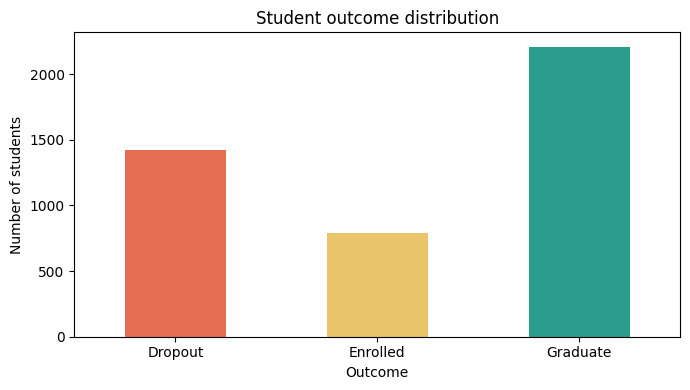

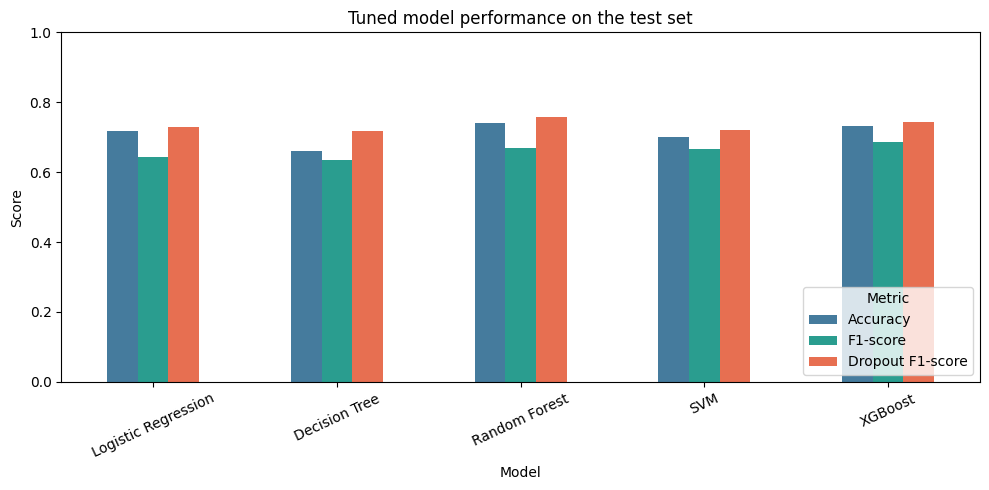

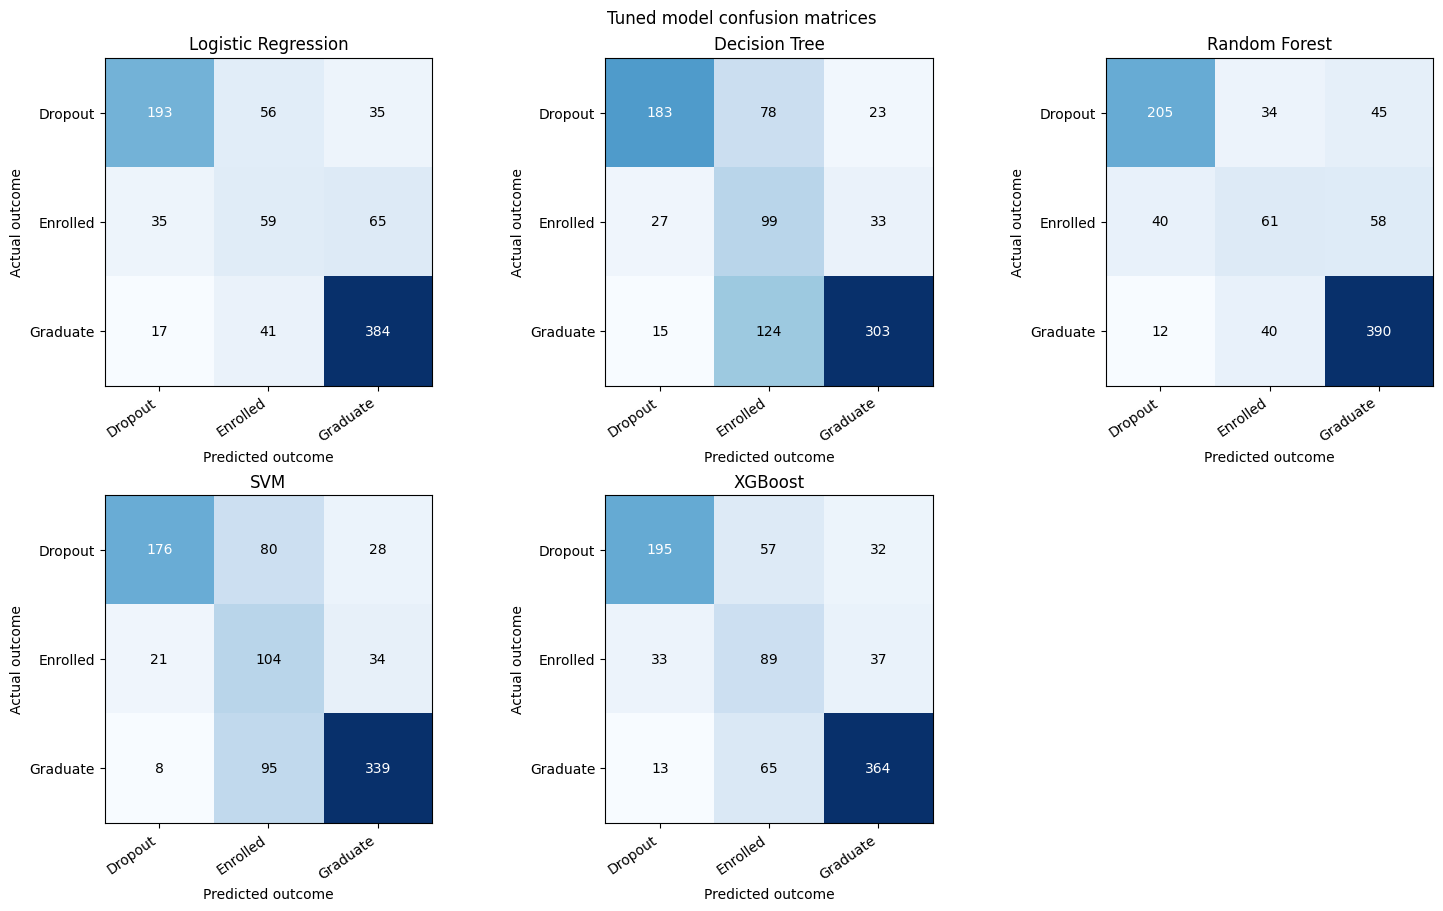

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if 'project_dir' not in globals():
    project_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'student_dropout_prediction']
    project_dir = next(
        (candidate for candidate in project_candidates if (candidate / 'dataset' / 'data.csv').exists()),
        None,
    )
    if project_dir is None:
        raise FileNotFoundError('Could not locate the project dataset. Run the data-loading cell first.')

plot_evaluation = joblib.load(project_dir / 'ml_training' / 'notebook_outputs' / 'evaluation_details.pkl')
if 'tuned_results_df' not in globals() or 'confusion_matrices' not in globals():
    tuned_results_df = pd.DataFrame(plot_evaluation['tuned_results'])
    confusion_matrices = {
        result['Model']: result['Confusion Matrix']
        for result in plot_evaluation['tuned_results']
    }

if 'df' not in globals():
    df = pd.read_csv(project_dir / 'dataset' / 'data.csv', sep=';')
    df.columns = [str(column).strip() for column in df.columns]

class_labels = label_encoder.classes_ if 'label_encoder' in globals() else plot_evaluation['target_classes']
class_counts = df['Target'].value_counts().reindex(class_labels, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 4))
class_counts.plot(kind='bar', ax=ax, color=['#e76f51', '#e9c46a', '#2a9d8f'])
ax.set(title='Student outcome distribution', xlabel='Outcome', ylabel='Number of students')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

score_columns = ['Accuracy', 'F1-score', 'Dropout F1-score']
score_comparison = tuned_results_df.set_index('Model')[score_columns]
ax = score_comparison.plot(
    kind='bar', figsize=(10, 5), ylim=(0, 1),
    color=['#457b9d', '#2a9d8f', '#e76f51'],
)
ax.set(title='Tuned model performance on the test set', xlabel='Model', ylabel='Score')
ax.legend(title='Metric', loc='lower right')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for ax, (model_name, matrix) in zip(axes.flat, confusion_matrices.items()):
    matrix = np.asarray(matrix)
    ax.imshow(matrix, cmap='Blues')
    ax.set(title=model_name, xlabel='Predicted outcome', ylabel='Actual outcome')
    ax.set_xticks(range(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=35, ha='right')
    ax.set_yticks(range(len(class_labels)))
    ax.set_yticklabels(class_labels)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            text_color = 'white' if matrix[row, column] > matrix.max() / 2 else 'black'
            ax.text(column, row, matrix[row, column], ha='center', va='center', color=text_color)

for ax in axes.flat[len(confusion_matrices):]:
    ax.set_visible(False)

fig.suptitle('Tuned model confusion matrices')
plt.show()

## Final app model evaluation

Run this cell independently to reproduce the app's final model score. It uses the same stratified 80/20 split, random seed, engineered features, and Random Forest settings as the app's saved Experiment 2 benchmark. This is the single accuracy to report for the current app model.

In [ ]:
.venv/
__pycache__/
.env
*.db
*.joblib
*.pkl
models/
dataset/
oulad_dataset/Set-Location D:\sdps; Get-Location@('.venv/', 'venv/', 'env/', '__pycache__/', '*.py[cod]', '.env', '.ipynb_checkpoints/', '*.db') | Set-Content -Encoding utf8 .gitignore@('.venv/', 'venv/', 'env/', '__pycache__/', '*.py[cod]', '.env', '.ipynb_checkpoints/', '*.db') | Set-Content -Encoding utf8 .gitignoreimport sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

if 'project_dir' not in globals():
    project_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'student_dropout_prediction']
    project_dir = next(
        (candidate for candidate in project_candidates if (candidate / 'dataset' / 'data.csv').exists()),
        None,
    )
    if project_dir is None:
        raise FileNotFoundError('Could not locate dataset/data.csv. Open the notebook from the project or set project_dir.')

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from ml_training.feature_engineering import AcademicFeatureEngineer

app_df = pd.read_csv(project_dir / 'dataset' / 'data.csv', sep=';')
app_df.columns = [str(column).strip() for column in app_df.columns]
app_df = app_df.replace(r'^\s*$', np.nan, regex=True)
app_df = app_df.drop_duplicates().dropna(subset=['Target']).reset_index(drop=True)
X_app = app_df.drop(columns=['Target'])
y_app = app_df['Target'].astype(str).str.strip()
X_app_train, X_app_test, y_app_train, y_app_test = train_test_split(
    X_app, y_app, test_size=0.2, stratify=y_app, random_state=42
)

feature_engineer = AcademicFeatureEngineer().fit(X_app_train)
X_app_train_engineered = feature_engineer.transform(X_app_train)
X_app_test_engineered = feature_engineer.transform(X_app_test)
app_model_features = list(X_app_train_engineered.columns)
app_model_pipeline = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), app_model_features),
    ])),
    ('model', RandomForestClassifier(
        n_estimators=180,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
    )),
])
app_model_pipeline.fit(X_app_train_engineered, y_app_train)
app_predictions = app_model_pipeline.predict(X_app_test_engineered)
app_accuracy = accuracy_score(y_app_test, app_predictions)
app_macro_f1 = f1_score(y_app_test, app_predictions, average='macro')

print('Final app model: Random Forest with engineered academic features')
print(f'Test accuracy: {app_accuracy:.2%}')
print(f'Macro F1: {app_macro_f1:.4f}')
print(f'Test samples: {len(y_app_test)}')

app_results_path = project_dir / 'models' / 'model_results.csv'
if app_results_path.exists():
    saved_app_results = pd.read_csv(app_results_path)
    matching_rows = saved_app_results[
        saved_app_results['Experiment'].astype(str).str.contains('Experiment 2', case=False, na=False)
        & saved_app_results['Model'].astype(str).str.casefold().eq('random forest')
    ]
    if not matching_rows.empty:
        saved_app_result = matching_rows.iloc[0]
        saved_accuracy = float(saved_app_result['Accuracy'])
        print(f"Saved app benchmark accuracy: {saved_accuracy:.2%}")
        if abs(app_accuracy - saved_accuracy) > 1e-12:
            print('Note: the reproduced score differs from the saved app benchmark; check that both use the same dataset and package versions.')

        app_table_row = {
            'Model': 'Random Forest (app)',
            'Result': 'App benchmark - engineered features',
            'Accuracy': saved_accuracy,
            'Precision': saved_app_result['Precision'],
            'Recall': saved_app_result['Recall'],
            'F1-score': saved_app_result['Macro F1'],
            'Weighted F1': saved_app_result['Weighted F1'],
            'ROC-AUC': saved_app_result['ROC-AUC'],
        }
        if 'baseline_results_df' in globals():
            app_comparison_table = pd.concat(
                [baseline_results_df, pd.DataFrame([app_table_row])], ignore_index=True
            )
            print('11-feature baseline results and app benchmark (different experiments):')
            display(app_comparison_table.drop(columns=['Confusion Matrix'], errors='ignore'))
        else:
            print('App benchmark result:')
            display(pd.DataFrame([app_table_row]))

Final app model: Random Forest with engineered academic features
Test accuracy: 78.53%
Macro F1: 0.7188
Test samples: 885
Saved app benchmark accuracy: 78.53%
App benchmark result:


,Model,Result,Accuracy,Precision,Recall,F1-score,Weighted F1,ROC-AUC
0,Random Forest (app),App benchmark - engineered features,0.785311,0.743293,0.707209,0.71882,0.775353,0.886263
